# Figure 3: Value of Partial Coordination


In [8]:
file ='../Figures'


# import data
import pandas as pd
import os
import numpy as np

# function that creates dataframe from list of files in a path
def create_dataframe(path, tag):
# get all files in the path
    files = os.listdir(path)

    # create a dictionary to store all dataframes
    dfs = {}

    for file in files:
        if file.endswith('.csv'):
            # read the csv file
            df = pd.read_csv(path+file)

            if tag == 'results':
                WWTP = file.split('results_')[1]
                WWTP = WWTP.split('.csv')[0]
                if 'econ' not in WWTP:
                    dfs[WWTP] = df
            
            # if file includes tag in name
            elif tag in file:
                # create string with only the characters after "results_econ_"
                WWTP= file.split('results_econ_')[1]
                WWTP = WWTP.split('.csv')[0]
                dfs[WWTP] = df
                
    return dfs
                    

def create_df(WWTP, dfs):
    df = dfs[WWTP]
    df.rename(columns={df.columns[0]: 'Datetime'}, inplace=True)
    df.Datetime = pd.to_datetime(df.Datetime)
    
    return df

## Importing Figure files for individual WWTPs and overall cases

In [9]:
path_case_1 = '../Results/Non_Staged/No_coordination/'
path_case_2 = '../Results/Staged/No_coordination/'
path_case_3 = '../Results/Non_Staged/Partial_coordination/'
path_case_4 = '../Results/Staged/Partial_coordination/'
path_case_5 = '../Results/Non_Staged/Full_coordination/'
path_case_6 = '../Results/Staged/Full_coordination/'

dfs_econ_case_1 = create_dataframe(path_case_1, 'econ')
dfs_econ_case_2 = create_dataframe(path_case_2, 'econ')
dfs_econ_case_3 = create_dataframe(path_case_3, 'econ')
dfs_econ_case_4 = create_dataframe(path_case_4, 'econ')
dfs_econ_case_5 = create_dataframe(path_case_5, 'econ')
dfs_econ_case_6 = create_dataframe(path_case_6, 'econ')

dfs_results_case_1 = create_dataframe(path_case_1, 'results')
dfs_results_case_2 = create_dataframe(path_case_2, 'results')
dfs_results_case_3 = create_dataframe(path_case_3, 'results')
dfs_results_case_4 = create_dataframe(path_case_4, 'results')
dfs_results_case_5 = create_dataframe(path_case_5, 'results')
dfs_results_case_6 = create_dataframe(path_case_6, 'results')

In [10]:
path_sum_case_1 = '../Results/Non_Staged/No_coordination_summary.csv'
path_sum_case_2 = '../Results/Staged/No_coordination_summary.csv'
path_sum_case_3 = '../Results/Non_Staged/Partial_coordination_summary.csv'
path_sum_case_4 = '../Results/Staged/Partial_coordination_summary.csv'
path_sum_case_5 = '../Results/Non_Staged/Full_coordination_summary.csv'
path_sum_case_6 = '../Results/Staged/Full_coordination_summary.csv'

df_case_1 = pd.read_csv(path_sum_case_1)
df_case_2 = pd.read_csv(path_sum_case_2)
df_case_3 = pd.read_csv(path_sum_case_3)
df_case_4 = pd.read_csv(path_sum_case_4)
df_case_5 = pd.read_csv(path_sum_case_5)
df_case_6 = pd.read_csv(path_sum_case_6)

## Plot figures for partial coordination

### Plot minimized joint operating costs for S-PC case

In [11]:
WWTPs = ['Palo Alto', 'SJSC', 'Sunnyvale']

def create_combined_dfs(dt, tag_y, ):
    dfs = pd.read_csv(path + 'Partial_coordination_unit_cost_' + str(dt) + '.csv')
    dfs['Unit_Cost'] = dfs['Opex_total_new'] / dfs['r_total_new'] * (10**6/30)
    dfs['Unit_cost_of_removal'] = dfs['Opex_total_new'] / dfs['Additional_removal'] * (10**6/30)

    df_PA = dfs[(dfs['WWTP'] == 'Palo Alto') & (dfs['WWTP2'] == 'Palo Alto') & (dfs['WWTP3'] == 'Palo Alto')].copy()
    df_SJSC = dfs[(dfs['WWTP'] == 'SJSC') & (dfs['WWTP2'] == 'SJSC') & (dfs['WWTP3'] == 'SJSC')].copy()
    df_SV = dfs[(dfs['WWTP'] == 'Sunnyvale') & (dfs['WWTP2'] == 'Sunnyvale') & (dfs['WWTP3'] == 'Sunnyvale')].copy()

    df_PA_SJSC = dfs[(dfs['WWTP'] == 'Palo Alto') & (dfs['WWTP2'] == 'Palo Alto') & (dfs['WWTP3'] == 'SJSC')].copy()
    df_PA_SV = dfs[(dfs['WWTP'] == 'Palo Alto') & (dfs['WWTP2'] == 'Sunnyvale') & (dfs['WWTP3'] == 'Sunnyvale')].copy()
    df_SJSC_SV = dfs[(dfs['WWTP'] == 'SJSC') & (dfs['WWTP2'] == 'SJSC') & (dfs['WWTP3'] == 'Sunnyvale')].copy()

    df_all = dfs[(dfs['WWTP'] == 'Palo Alto') & (dfs['WWTP2'] == 'SJSC') & (dfs['WWTP3'] == 'Sunnyvale')].copy()

    # convert datetime column to datetime type
    # conver all dfs to datetime
    df_PA['datetime'] = pd.to_datetime(df_PA['datetime'])
    df_SJSC['datetime'] = pd.to_datetime(df_SJSC['datetime'])
    df_SV['datetime'] = pd.to_datetime(df_SV['datetime'])
    df_PA_SJSC['datetime'] = pd.to_datetime(df_PA_SJSC['datetime'])
    df_PA_SV['datetime'] = pd.to_datetime(df_PA_SV['datetime'])
    df_SJSC_SV['datetime'] = pd.to_datetime(df_SJSC_SV['datetime'])
    df_all['datetime'] = pd.to_datetime(df_all['datetime'])

    # Add column for 'WWTP_combo'to each dataframe
    df_PA['WWTP_combo'] = 'Palo Alto'
    df_SJSC['WWTP_combo'] = 'SJSC'
    df_SV['WWTP_combo'] = 'Sunnyvale'
    df_PA_SJSC['WWTP_combo'] = 'Palo Alto + SJSC'
    df_PA_SV['WWTP_combo'] = 'Palo Alto + Sunnyvale'
    df_SJSC_SV['WWTP_combo'] = 'SJSC + Sunnyvale'
    df_all['WWTP_combo'] = 'All three WWTPs'

    df_combined = pd.concat([df_PA, df_SJSC, df_SV, df_PA_SV, df_PA_SJSC, df_SJSC_SV, df_all], ignore_index=True)
    # remove any rows where L1, L2 or L3 is an empty array
    for col in ['L1', 'L2', 'L3']:
        df_combined = df_combined[df_combined[col].astype(str) != '[]']



    

    idx_min = df_combined.groupby(['Additional_removal'])[tag_y].idxmin()
    dfs_combined = df_combined.loc[idx_min].reset_index(drop=True)
    


    return dfs_combined, df_combined

In [12]:
import matplotlib.pyplot as plt
import pandas as pd


color_dict = {
    'SJSC': '#D57A6E',                # Keep: Soft terracotta
    'Sunnyvale': '#B79BB8',           # Keep: Muted lavender
    'Palo Alto': '#A3B89C',           # Keep: Sage green

    'SJSC + Sunnyvale': '#78A3A0',    # New: Cool jade (stronger teal contrast)
    'Palo Alto + SJSC': '#E2A974',    # New: Muted amber (warmer contrast)
    'Palo Alto + Sunnyvale': '#7D9FD1',  # New: Soft dusty blue (contrasts lavender/green)
    'All three WWTPs': '#C0C7A3'      # New: Blue-gray (neutral and distinguishable)
}


L_upgrades = ['SS', 'L2', 'L2upg3', 'L3']
L_upgrade_short= ['SS', 'L2', 'L3']
L_linestyle = {'L3': '--', 'L2': '-.', 'SS': '-', 'L2upg3': ':'}
colors_WWTP = {'SJSC': '#D57A6E', 'Sunnyvale': '#B79BB8', 'Palo Alto': '#A3B89C'}
upg_leg = {'L3':'Level 3', 'L2':'Level 2', 'SS': 'Sidestream treatment', 'L2upg3': 'Level 2 expanded to 3'}
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
lab_size = 7
leg_size = 6
line_wid = 0.75
bord_wid = 2



def plot_costs_combined_line(dts, plot_tag, tag_y):
    # Group by WWTP_combo and plot each group with a different color and shaded area
    
    fig, axs_b = plt.subplots(3, 1, figsize=(120/25.4, 70/25.4))
    
    for i,dt in enumerate(dts):
        #if plot_tag == 'all':
        df, dfs = create_combined_dfs(dt, tag_y='Opex_total_new')
        
        df.Additional_removal = df['Additional_removal']*0.001
        df = df.sort_values('Additional_removal')

        
        
        for wwtp_combo, group in df.groupby('WWTP_combo'):
            axs_b[i].plot(group['Additional_removal'], group[tag_y], 
                    #label=wwtp_combo, 
                    label = '',
                    color=color_dict[wwtp_combo], linewidth=1.5, linestyle='-')
            if plot_tag == 'min':
                axs_b[i].fill_between(group['Additional_removal'], group[tag_y], alpha=0.2, color=color_dict[wwtp_combo])
            

        #removal = {'May 2037':4585.215877353758, 'May 2047': 9784.118483481889}
        removal = df['Required_removal'].unique()[0]*0.001
        date = df['datetime'].dt.strftime('%b %Y').unique()[0]

        # plot vertical line for both removal dates
        axs_b[i].axvline(x=removal, color='black', linestyle='--', linewidth=0.75, label=f'Required subembayment TIN\nremoval in the given month')
        print(f"Plotting for date: {date}, removal: {removal}")
        
        if tag_y == 'Unit_Cost':
            axs_b[i].set_ylim([0, 5])
            axs_b[1].set_ylabel('Unit operating costs' + ' ($/lb TIN)', **hfont)
        elif tag_y == 'Opex_total_new':
            axs_b[i].set_ylim([0, 1.2])
            axs_b[1].set_ylabel('Joint operating costs' + ' ($ mil)', **hfont)

        # make legend vertically middle

        
        
        axs_b[i].set_xlim([0, 14])
        
        if i == 0:
            axs_b[i].legend(loc='upper right', prop={'family':'Helvetica', 'size':leg_size}, ncol = 1, frameon=False)

        if i == 2:
            axs_b[i].set_xlabel('Required subembayment TIN removal (1,000 lb/day)', **hfont)
        else:
            axs_b[i].set_xticklabels([])

    
    fig_labels = ['i', 'ii', 'iii']
    for i,ax in enumerate(axs_b):
        ax.text(0.02, 0.9, fig_labels[i], transform=ax.transAxes, fontsize=leg_size, fontweight='bold', va='top', ha='left')
        ax.xaxis.set_ticks_position('both')
        ax.tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=leg_size, labelfontfamily= 'Helvetica')
        for spine in ax.spines.values():
            spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)
        axs_b[i].set_xlim(axs_b[2].get_xlim())
    


    


    fig.tight_layout()
    fig.savefig(file + "/Fig_3a" + ".svg", format="svg", dpi=300)
    
    return fig, axs_b


Plotting for date: Jun 2036, removal: 4.11909127162117
Plotting for date: Jun 2045, removal: 8.787662150640667
Plotting for date: Jun 2054, removal: 13.466674496155983


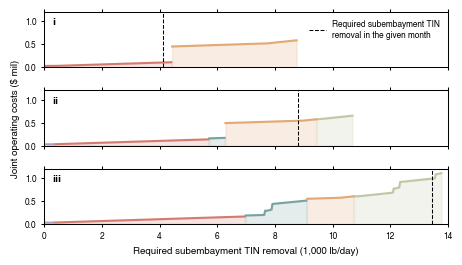

In [13]:
path = '../Results/Unit_cost_by_WWTP/'

dts = ['Jun_2036', 'Jun_2045', 'Jun_2054']
fig, axs_b = plot_costs_combined_line(dts, plot_tag='min', tag_y='Opex_total_new')

### Plot Monthly TIN removal for S-NC vs S-PC

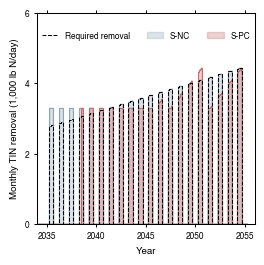

In [14]:
# S-NC to S-PC in Palo Alto

import matplotlib.pyplot as plt

WWTPs = sorted(dfs_results_case_2.keys())
WWTPs = ['SJSC', 'Sunnyvale', 'Palo Alto']
labels = ['SS', 'L2', 'L2upg3', 'L3']
colors = {'L3':'black', 'L2':'red', 'L2upg3':'green', 'SS': 'pink'}
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
leg_size = 6
line_wid = 0.75
bord_wid = 2


fig, axs = plt.subplots(1, 1, figsize=(70/25.4, 70/25.4))
WWTP = 'Palo Alto'


df_no_coord = create_df(WWTP, dfs_results_case_2)
df_coord = create_df(WWTP, dfs_results_case_4)

axs.step(df_coord.Datetime, df_coord.Required_removal*0.001, '--', color = 'k',label = 'Required removal', linewidth = line_wid, zorder=4)

axs.step(df_no_coord.Datetime, df_no_coord.Total_removal*0.001, '-', color = '#8BA4B9',label = '', linewidth = line_wid)
axs.fill_between(df_no_coord.Datetime, df_no_coord.Total_removal*0.001, alpha=0.3, color = '#8BA4B9', label = 'S-NC')

axs.step(df_coord.Datetime, df_coord.Total_removal*0.001, '-', color = '#C96C6C',label = '', linewidth = line_wid)
axs.fill_between(df_coord.Datetime, df_coord.Total_removal*0.001, alpha=0.3, color = '#C96C6C', label = 'S-PC')



#axs.set_ylabel('Palo Alto\n TIN removal (lb N/day)', **hfont)
axs.set_ylabel('Monthly TIN removal (1,000 lb N/day)', **hfont)


df_years = create_df(WWTP, dfs_econ_case_1)
axs.set_xticks([df_years.Datetime[t] for t in range(0, len(df_years.Datetime), 5)])
axs.set_xticklabels([df_years.Datetime[t].strftime('%Y') for t in range(0, len(df_years.Datetime), 5)], **hfont_ticks)
axs.set_xticklabels([])
axs.tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')

# set axis limits
axs.set_ylim(0, 6)
axs.set_yticks([0, 2, 4, 6])

df_years = create_df(WWTP, dfs_econ_case_1)
axs.set_xticks([df_years.Datetime[t] for t in range(0, len(df_years.Datetime), 5)])
axs.set_xticklabels([df_years.Datetime[t].strftime('%Y') for t in range(0, len(df_years.Datetime), 5)], **hfont_ticks)
axs.set_xlabel('Year', **hfont)
axs.tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')

#axs.set_xlim([df_years.Datetime[9], df_years.Datetime[30]])
axs.set_xlim([np.datetime64('2034-01-01'),np.datetime64('2056-01-01')])
axs.legend(loc='upper center', prop={'family':'Helvetica', 'size':leg_size}, frameon=False, bbox_to_anchor=(0.5, 0.95), ncol = 3)

axs.xaxis.set_ticks_position('both')
axs.tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=leg_size)
for spine in axs.spines.values():
    spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)


fig.tight_layout()    
fig.savefig(file + "/Fig_3b.svg", format="svg", dpi=300)

In [15]:
### Figure S4

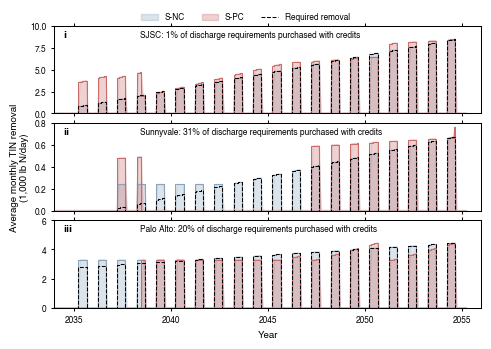

In [16]:
#comparing case 2 to case 4

import matplotlib.pyplot as plt

WWTPs = sorted(dfs_results_case_2.keys())
WWTPs = ['SJSC', 'Sunnyvale', 'Palo Alto']
labels = ['SS', 'L2', 'L2upg3', 'L3']
colors = {'L3':'black', 'L2':'red', 'L2upg3':'green', 'SS': 'pink'}
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
leg_size = 6
line_wid = 0.75
bord_wid = 2


fig, axs = plt.subplots(len(WWTPs), 1, figsize=(120/25.4, 85/25.4))
ciel = -(len(WWTPs)//-2)-1
for i, WWTP in enumerate(WWTPs):
    df_no_coord = create_df(WWTP, dfs_results_case_2)
    df_coord = create_df(WWTP, dfs_results_case_4)
    
    

    if WWTP == 'SJSC':
        axs[i].step(df_no_coord.Datetime, df_no_coord.Total_removal*0.001, '-', color = '#8BA4B9',label = '', linewidth = line_wid)
        axs[i].fill_between(df_no_coord.Datetime, df_no_coord.Total_removal*0.001, alpha=0.3, color = '#8BA4B9', label = 'S-NC')
        axs[i].step(df_coord.Datetime, df_coord.Total_removal*0.001, '-', color = '#C96C6C',label = '', linewidth = line_wid)
        axs[i].fill_between(df_coord.Datetime, df_coord.Total_removal*0.001, alpha=0.3, color = '#C96C6C', label = 'S-PC')

        axs[i].step(df_coord.Datetime, df_coord.Required_removal*0.001, '--', color = 'k',label = 'Required removal', linewidth = line_wid)
    else:
        axs[i].step(df_no_coord.Datetime, df_no_coord.Total_removal*0.001, '-', color = '#8BA4B9',label = '', linewidth = line_wid)
        axs[i].fill_between(df_no_coord.Datetime, df_no_coord.Total_removal*0.001, alpha=0.3, color = '#8BA4B9', label = '')
        axs[i].step(df_coord.Datetime, df_coord.Total_removal*0.001, '-', color = '#C96C6C',label = '', linewidth = line_wid)
        axs[i].fill_between(df_coord.Datetime, df_coord.Total_removal*0.001, alpha=0.3, color = '#C96C6C', label = '')

        axs[i].step(df_coord.Datetime, df_coord.Required_removal*0.001, '--', color = 'k',label = '', linewidth = line_wid)

    if i == ciel:
        axs[i].set_ylabel('Average monthly TIN removal\n(1,000 lb N/day)', **hfont)

    
    # calculate volume purchased
    df_coord['Days_in_month'] = df_coord.Datetime.dt.days_in_month
    df_coord['TIN_in_month'] = df_coord['Days_in_month'] * df_coord['Total_removal']
    df_coord['Required_removal_monthly'] = df_coord['Days_in_month'] * df_coord['Required_removal']
    df_coord['Volume_purchased'] = np.array(df_coord['Required_removal_monthly'] - df_coord['TIN_in_month']).clip(min=0)
    per_limit = round(df_coord.Volume_purchased.sum()/df_coord.Required_removal_monthly.sum()*100)


    df_years = create_df(WWTP, dfs_econ_case_1)
    axs[i].set_xticks([df_years.Datetime[t] for t in range(0, len(df_years.Datetime), 5)])
    axs[i].set_xticklabels([df_years.Datetime[t].strftime('%Y') for t in range(0, len(df_years.Datetime), 5)], **hfont_ticks)
    axs[i].set_xticklabels([])
    axs[i].tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')
    title_lab = WWTP+ ': ' + str(per_limit) + '% of discharge requirements purchased with credits'
    axs[i].text(0.2, 0.95, title_lab, transform=axs[i].transAxes, fontsize=leg_size, fontname='Helvetica' , va='top', ha='left')



# set axis limits
axs[2].set_ylim(0, 6)
axs[2].set_yticks([0, 2, 4, 6])
axs[0].set_ylim(0, 10)
axs[0].set_yticks([0, 2.5, 5, 7.5, 10])
axs[1].set_ylim(0, 0.8)
axs[1].set_yticks([0, 0.2, 0.4, 0.6, 0.8])


df_years = create_df(WWTP, dfs_econ_case_1)
axs[2].set_xticks([df_years.Datetime[t] for t in range(0, len(df_years.Datetime), 5)])
axs[2].set_xticklabels([df_years.Datetime[t].strftime('%Y') for t in range(0, len(df_years.Datetime), 5)], **hfont_ticks)
axs[2].set_xlabel('Year', **hfont)
axs[2].tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')

fig.legend(loc='upper center', prop={'family':'Helvetica', 'size':leg_size}, frameon=False, bbox_to_anchor=(0.5, 1), ncol = 3)

axs[2].set_xlim([np.datetime64('2034-01-01'),np.datetime64('2056-01-01')])

fig_labels = ['i', 'ii', 'iii']
for i,ax in enumerate(axs):
    ax.text(0.02, 0.95, fig_labels[i], transform=ax.transAxes, fontsize=leg_size, fontweight='bold', va='top', ha='left')
    ax.xaxis.set_ticks_position('both')
    ax.tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=leg_size)
    for spine in ax.spines.values():
        spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)
    axs[i].set_xlim(axs[2].get_xlim())
    
fig.tight_layout(pad=0.05, rect=[0, 0, 1, 0.95])
fig.savefig(file + "/SI/S4.svg", format="svg", dpi=300)

### Figure 3d

Total opex costs for Staged: 43.47 35.81
Total opex costs for Non-Staged: 43.47 35.14
Total opex savings for Staged: 7.66
Total opex savings for Non-Staged: 8.33
Percent opex savings for Staged: 18 %
Percent opex savings for Non-Staged: 19 %
SJSC
     Total opex savings for staged= 0.17
     Total opex savings for non-staged= -1.03
Sunnyvale
     Total opex savings for staged= 0.87
     Total opex savings for non-staged= 0.56
Palo Alto
     Total opex savings for staged= 6.63
     Total opex savings for non-staged= 8.81


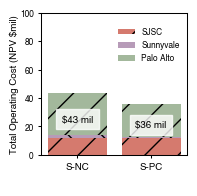

In [17]:
import matplotlib.pyplot as plt

ind = ['S-NC', 'S-PC']
ind_2 = ['NS-NC', 'NS-PC']
ind_tick = np.arange(len(ind))


WWTPs = ['SJSC', 'Sunnyvale', 'Palo Alto']
df_results_opex_Staged = pd.DataFrame(index=WWTPs, columns=['NC', 'PC'])
df_results_opex_Nonstaged = pd.DataFrame(index=WWTPs, columns=['NC', 'PC'])


for WWTP in WWTPs:
    df_results_opex_Staged.loc[WWTP, 'NC'] = df_case_2[df_case_2['Abbreviation'] == WWTP]['Total_opex'].values[0]
    df_results_opex_Staged.loc[WWTP, 'PC'] = df_case_4[df_case_4['Abbreviation'] == WWTP]['Total_opex'].values[0]
    df_results_opex_Nonstaged.loc[WWTP, 'NC'] = df_case_1[df_case_1['Abbreviation'] == WWTP]['Total_opex'].values[0]
    df_results_opex_Nonstaged.loc[WWTP, 'PC'] = df_case_3[df_case_3['Abbreviation'] == WWTP]['Total_opex'].values[0]
    
colors = ['red','purple','green']
colors = ['#D57A6E', '#B79BB8', '#A3B89C']
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
lab_size = 7
leg_size = 6
line_wid = 0.75
bord_wid = 2


fig, axs = plt.subplots(1, 1, figsize=(52.5/25.4, 52.5/25.4))


# plot Staged
axs.bar(ind_tick, df_results_opex_Staged.loc[WWTPs[0]].values, label = WWTPs[0] , color=colors[0], hatch='/')
axs.bar(ind_tick , df_results_opex_Staged.loc[WWTPs[1]].values, label = WWTPs[1]  , color=colors[1], bottom = df_results_opex_Staged.loc[WWTPs[0]].values, hatch= '\\')
bars = axs.bar(ind_tick , df_results_opex_Staged.loc[WWTPs[2]].values, label = WWTPs[2]  , color=colors[2], 
           bottom = df_results_opex_Staged.loc[WWTPs[0]].values + df_results_opex_Staged.loc[WWTPs[1]].values, hatch='/')

for a,bar in enumerate(bars):
        yval = sum(df_results_opex_Staged.loc[WWTPs[i]].values[a] for i in range(len(WWTPs)))
        t = axs.text(bar.get_x() + bar.get_width()/2.0, yval - yval/2, '$' + str(int(round(yval,0))) + ' mil', 
                    va='bottom', ha='center', color='black', fontsize=lab_size, font='Helvetica')
        t.set_bbox(dict(facecolor='white', alpha=0.8, edgecolor='white'))

#remove xticks
axs.set_ylabel('Total Operating Cost (NPV $mil)', **hfont)
axs.legend(prop={'family':'Helvetica', 'size':leg_size}, frameon=False, loc='upper right', bbox_to_anchor=(1, 0.95))
axs.tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')
axs.set_xticks(ind_tick, ind, **hfont) 


plt.yticks(**hfont_ticks)

plt.tight_layout()


x_label_coord = -0.15  # Adjust this value to control the x position of all y-labels
axs.yaxis.set_label_coords(x_label_coord, 0.5)  # Align at x=-0.1, center vertically (y=0.5)
axs.tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=leg_size)
axs.tick_params(axis='x', labelsize=lab_size)
for spine in axs.spines.values():
    spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)

axs.set_ylim(0, 100)
axs.set_xlabel(' ', **hfont_ticks)

fig.tight_layout()
fig.savefig(file + "/Fig_3d.svg", bbox_inches="tight", format="svg", dpi=300)

print('Total opex costs for Staged:', round(sum(df_results_opex_Staged.NC),2), round(sum(df_results_opex_Staged.PC),2))
print('Total opex costs for Non-Staged:', round(sum(df_results_opex_Nonstaged.NC),2), round(sum(df_results_opex_Nonstaged.PC),2))
print('Total opex savings for Staged:', round(sum(df_results_opex_Staged.NC)-sum(df_results_opex_Staged.PC),2))
print('Total opex savings for Non-Staged:', round(sum(df_results_opex_Nonstaged.NC)-sum(df_results_opex_Nonstaged.PC),2))
print('Percent opex savings for Staged:', round((sum(df_results_opex_Staged.NC)-sum(df_results_opex_Staged.PC))/sum(df_results_opex_Staged.NC)*100), '%')
print('Percent opex savings for Non-Staged:', round((sum(df_results_opex_Nonstaged.NC)-sum(df_results_opex_Nonstaged.PC))/sum(df_results_opex_Nonstaged.NC)*100), '%')
for WWTP in WWTPs:
    print(WWTP)
    print('     Total opex savings for staged=', np.round(df_results_opex_Staged.NC[WWTP]-df_results_opex_Staged.PC[WWTP],2))
    print('     Total opex savings for non-staged=', np.round(df_results_opex_Nonstaged.NC[WWTP]-df_results_opex_Nonstaged.PC[WWTP],2))

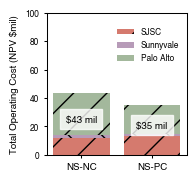

In [18]:
import matplotlib.pyplot as plt

ind = ['S-NC', 'S-PC']
ind_2 = ['NS-NC', 'NS-PC']
ind_tick = np.arange(len(ind_2))


WWTPs = ['SJSC', 'Sunnyvale', 'Palo Alto']
df_results_opex_Staged = pd.DataFrame(index=WWTPs, columns=['NC', 'PC'])
df_results_opex_Nonstaged = pd.DataFrame(index=WWTPs, columns=['NC', 'PC'])


for WWTP in WWTPs:
    df_results_opex_Staged.loc[WWTP, 'NC'] = df_case_2[df_case_2['Abbreviation'] == WWTP]['Total_opex'].values[0]
    df_results_opex_Staged.loc[WWTP, 'PC'] = df_case_4[df_case_4['Abbreviation'] == WWTP]['Total_opex'].values[0]
    df_results_opex_Nonstaged.loc[WWTP, 'NC'] = df_case_1[df_case_1['Abbreviation'] == WWTP]['Total_opex'].values[0]
    df_results_opex_Nonstaged.loc[WWTP, 'PC'] = df_case_3[df_case_3['Abbreviation'] == WWTP]['Total_opex'].values[0]
    
colors = ['red','purple','green']
colors = ['#D57A6E', '#B79BB8', '#A3B89C']
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
lab_size = 7
leg_size = 6
line_wid = 0.75
bord_wid = 2


fig, axs = plt.subplots(1, 1, figsize=(52.5/25.4, 52.5/25.4))


# plot Staged
axs.bar(ind_tick, df_results_opex_Nonstaged.loc[WWTPs[0]].values, label = WWTPs[0] , color=colors[0], hatch='/')
axs.bar(ind_tick , df_results_opex_Nonstaged.loc[WWTPs[1]].values, label = WWTPs[1]  , color=colors[1], bottom = df_results_opex_Nonstaged.loc[WWTPs[0]].values, hatch= '\\')
bars = axs.bar(ind_tick , df_results_opex_Nonstaged.loc[WWTPs[2]].values, label = WWTPs[2]  , color=colors[2], 
           bottom = df_results_opex_Nonstaged.loc[WWTPs[0]].values + df_results_opex_Nonstaged.loc[WWTPs[1]].values, hatch='/')

for a,bar in enumerate(bars):
        yval = sum(df_results_opex_Nonstaged.loc[WWTPs[i]].values[a] for i in range(len(WWTPs)))
        t = axs.text(bar.get_x() + bar.get_width()/2.0, yval - yval/2, '$' + str(int(round(yval,0))) + ' mil', 
                    va='bottom', ha='center', color='black', fontsize=lab_size, font='Helvetica')
        t.set_bbox(dict(facecolor='white', alpha=0.8, edgecolor='white'))

#remove xticks
axs.set_ylabel('Total Operating Cost (NPV $mil)', **hfont)
axs.legend(prop={'family':'Helvetica', 'size':leg_size}, frameon=False, loc='upper right', bbox_to_anchor=(1, 0.95))
axs.tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica')
axs.set_xticks(ind_tick, ind_2, **hfont) 


plt.yticks(**hfont_ticks)

plt.tight_layout()


#x_label_coord = -0.15  # Adjust this value to control the x position of all y-labels
#axs.yaxis.set_label_coords(x_label_coord, 0.5)  # Align at x=-0.1, center vertically (y=0.5)
axs.tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=leg_size)
axs.tick_params(axis='x', labelsize=lab_size)
for spine in axs.spines.values():
    spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)

axs.set_ylim(0, 100)
axs.set_xlabel(' ', **hfont_ticks)

fig.tight_layout()
fig.savefig(file + "/SI/S5.svg", bbox_inches="tight", format="svg", dpi=300)